# NYC Taxi Trip Duration: Exploratory Data Analysis

## Project Overview

The objective of this project is to predict the duration of taxi trips in New York City using the available trip records.

The notebook progresses from an initial inspection of the original data
to feature engineering and a preview of the enriched dataset. The final
section outlines the deeper visual analysis planned to investigate the
distributions and relationships of the original and engineered features.

Model training and feature-selection experiments are handled separately.
The predictive value of the engineered features will be evaluated during
those experiments rather than assumed from the EDA alone.

## Table of Contents

1. Libraries and Configuration
2. Data Loading and Initial Checks
3. Initial Exploration of the Original Features
4. Why Feature Engineering?
5. Feature Engineering
   - Datetime Feature Extraction
   - Haversine Distance
   - Manhattan-Style Distance
   - Pickup Bearing
   - Airport Proximity
   - Rush-Hour Distance Interactions
   - Spatial Grid and Day–Hour Categories
   - Cyclical Time Features
   - Distance Relationship Features
   - Target Log Transformation
   - Log-Scaled Geographic Distances
6. Feature-Engineered Dataset Preview
   - Data Inspection and Quality Checks
   - Column Reference
   - Numerical and Categorical Feature Selection
7. Deep EDA: Planned Visualizations

---

## Libraries and Configuration

The notebook uses pandas for data inspection and custom project modules for data loading, feature engineering, and visualization. Keeping these operations in separate modules allows the same transformations to be reused in the modeling scripts.

In [1]:
import pandas as pd

pd.options.display.max_columns = 100
from taxi_trip_duration.manipulation.data_helper import *
from taxi_trip_duration.manipulation.feature_engineering import *
from taxi_trip_duration.visualization.plotting import *

## Data Loading and Initial Checks

The training, validation, and test sets were prepared separately during the data-splitting stage. For this notebook, the training and validation records are combined for descriptive exploration, while the test set remains unused.

Because some feature choices may be influenced by these observations, validation performance should still be interpreted as a model-selection result rather than a completely independent final evaluation. The test set should remain reserved for the final evaluation.

In [2]:
train, val, _ = load_dataset()
df = pd.concat([train, val], ignore_index=True)
df.sample(5)

Loading datasets from: dataset/split/


,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
686942,id0891072,1,2016-03-20 11:09:12,1,-73.953293,40.775620,-73.990143,40.762096,N,1116
536428,id0918708,2,2016-04-07 07:14:28,6,-73.993019,40.742725,-73.974197,40.737148,N,363
671157,id0065825,1,2016-02-09 03:01:09,1,-74.002022,40.729855,-73.983810,40.754890,N,312
110864,id3937126,1,2016-02-23 17:53:55,1,-74.010178,40.720387,-73.995796,40.748920,N,964
266321,id1364209,2,2016-04-13 18:47:20,1,-73.983040,40.760830,-73.970581,40.755840,N,280


### Dataset Structure

Before applying transformations, it is useful to identify the original columns and the information each one represents.

| Column | Description |
|---|---|
| `id` | Identifier assigned to a trip record. |
| `vendor_id` | Code identifying the trip-record provider. |
| `pickup_datetime` | Timestamp when the meter was engaged. |
| `passenger_count` | Recorded number of passengers. |
| `pickup_longitude` | Longitude of the pickup location. |
| `pickup_latitude` | Latitude of the pickup location. |
| `dropoff_longitude` | Longitude of the drop-off location. |
| `dropoff_latitude` | Latitude of the drop-off location. |
| `store_and_fwd_flag` | Indicates whether the trip record was stored in vehicle memory before being sent to the provider (`Y`) or sent directly (`N`). |
| `trip_duration` | Trip duration in seconds; the prediction target. |

These columns provide identifiers, categorical information, a timestamp, geographic coordinates, and the target variable. The initial checks below establish their data types and help identify possible quality issues before any new features are created.

---

### Initial Data-Quality Checks

The following checks summarize the dataset's completeness, duplicated records, and other basic data-quality characteristics. They provide an initial overview rather than a complete assessment of whether every value is realistic.

In particular, the absence of missing values does not guarantee that coordinates, passenger counts, or trip durations are valid. Those values require separate plausibility checks during the exploration.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1229319 entries, 0 to 1229318
Data columns (total 10 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1229319 non-null  str    
 1   vendor_id           1229319 non-null  int64  
 2   pickup_datetime     1229319 non-null  str    
 3   passenger_count     1229319 non-null  int64  
 4   pickup_longitude    1229319 non-null  float64
 5   pickup_latitude     1229319 non-null  float64
 6   dropoff_longitude   1229319 non-null  float64
 7   dropoff_latitude    1229319 non-null  float64
 8   store_and_fwd_flag  1229319 non-null  str    
 9   trip_duration       1229319 non-null  int64  
dtypes: float64(4), int64(3), str(3)
memory usage: 93.8 MB


In [4]:
checking_data(df)

Data Diagnostics:
 - Shape              : (1229319, 10)
 - Missing Values     : 0
 - Duplicate Records  : 0


### Data Diagnostics and Quality Assessment

The initial checks on the combined training and validation data indicate the following:

- **Dataset size:** 1,229,319 records and 10 original features.
- **Completeness:** no missing values were found.
- **Duplicate records:** no duplicate rows were found by the check used in this notebook.
- **Data types:** geographic coordinates are stored as `float64`; `passenger_count`, `vendor_id`, and `trip_duration` are stored as `int64`.
- **Timestamp representation:** `pickup_datetime` is currently an object/string column, so it needs parsing before useful calendar and clock components can be extracted.

These checks suggest that explicit missing-value imputation and duplicate-row removal are not required for the inspected data. They do not, by themselves, confirm that all values are plausible: coordinate ranges, unusually short or long trips, and other outliers may still warrant separate investigation.

---

## Initial Exploration of the Original Features

The initial exploration focuses on a few questions that can be answered before creating additional features:

- What does the distribution of `trip_duration` look like?
- Are there coordinates that appear far from the main NYC data cluster?
- Are there extreme observations that need closer investigation?

At this stage, the goal is to identify patterns and questions for further analysis, not to make final decisions about filtering observations.


---

### Target Variable: `trip_duration`

Trip duration is recorded in seconds and is the target the model will predict. Examining its distribution helps us understand the range of trip durations and determine whether a small number of long trips substantially extend the distribution's right tail.

The following visualization provides two complementary views of the target:

- **Raw duration:** the left panel displays trips with durations below 7,200 seconds (two hours). Restricting the displayed observations makes the distribution of shorter trips easier to inspect.
- **Log-transformed duration:** the right panel displays the `log1p` transformation of trip duration across the full dataset.

The logarithmic transformation compresses larger values and changes the scale of the target. It is a candidate transformation to evaluate during model development, rather than a requirement for linear models.

Because the two panels use different subsets and scales, they should be interpreted as complementary views rather than a direct comparison of identical distributions.

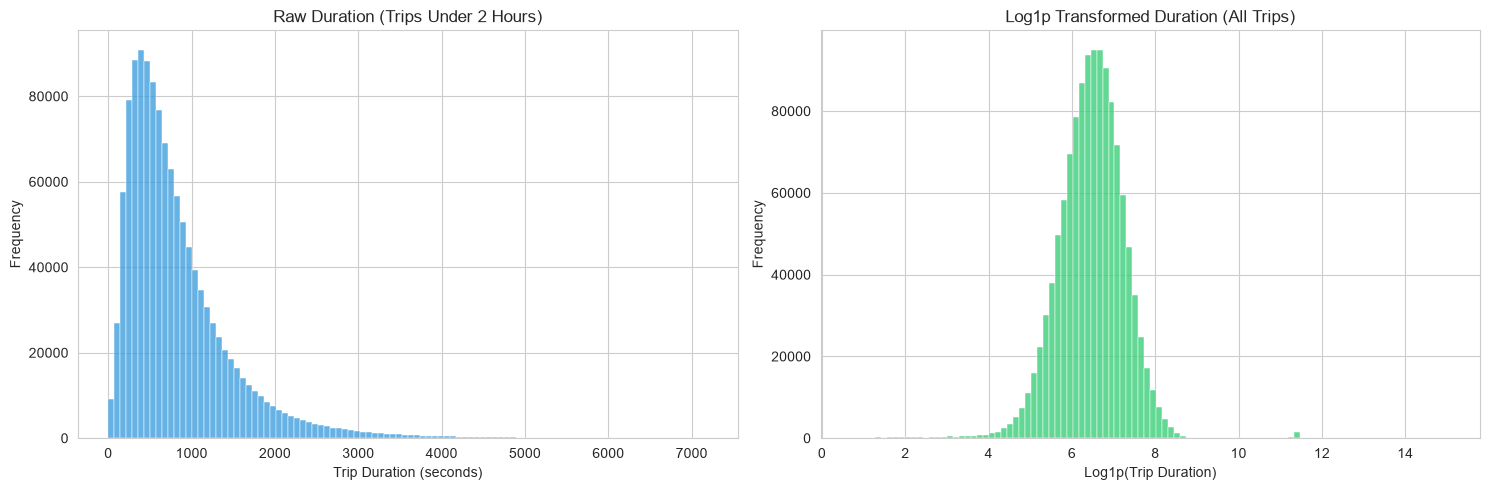

In [5]:
plot_target_distribution(df)

**What to examine**

The left panel helps us inspect the distribution of trips shorter than two hours, while the right panel shows how the logarithmic transformation represents the target across all observations.

Check whether the transformed distribution is more compact and whether a substantial right tail remains. The transformation compresses large durations, but the plot alone cannot establish that unusually long trips are erroneous or that the transformation will improve predictive performance.

The decision to use the transformed target will be evaluated through model-validation experiments.

---

### Geographic Distribution of Pickup Locations

The pickup coordinates describe where each trip begins. Visualizing these coordinates helps us examine their spatial concentration and identify patterns within the New York City area.

The plotting function selects a reproducible random sample of up to 100,000 records and displays pickup locations within a predefined geographic window:

- Longitude: -74.5 to -73.3
- Latitude: 40.4 to 41.2

These axis limits focus the visualization on the selected geographic region. Coordinates outside this window are not visible in the plot, so this visualization cannot establish whether the full dataset contains GPS anomalies farther outside the displayed area.

The plot also includes pickup locations only; it does not display drop-off locations.

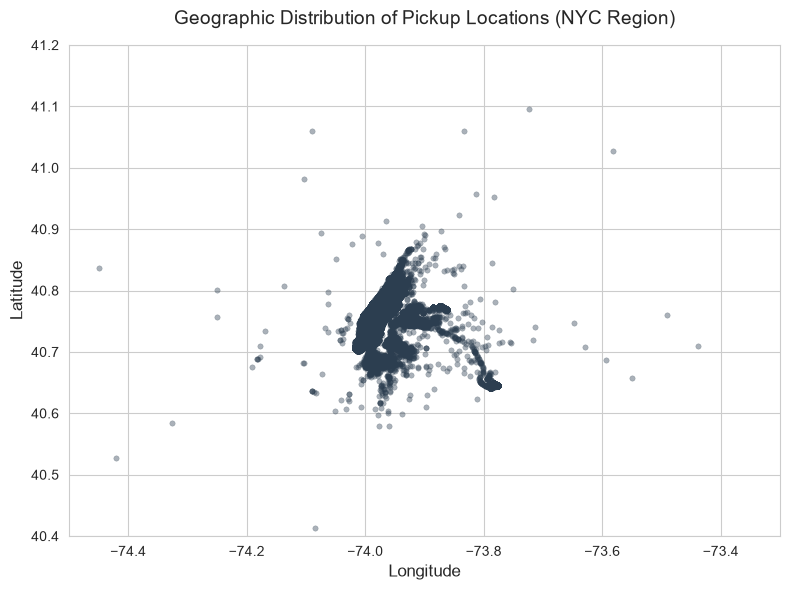

In [6]:
plot_geographic_distribution(df, n_samples=100000)

**What to examine**

Examine the concentration of pickup locations within the displayed region. Look for dense clusters, differences in spatial coverage, and isolated points that may deserve closer investigation.

Because the plot uses a fixed geographic window and a sample of the dataset, its conclusions are limited to the visible observations. Points outside the window cannot be assessed using this figure alone.

To investigate potential GPS errors throughout the dataset, a separate analysis of the full coordinate ranges and potentially invalid locations is needed. Unusual coordinates should be investigated rather than automatically classified as errors.

---

### Preliminary Outlier Strategy

No rows are removed at this stage. The initial plots identify observations that may deserve further investigation, but they are not sufficient on their own to determine which records should be excluded.

Keeping all observations for now avoids making a filtering decision before its impact has been measured. It does **not** mean that every extreme observation is valid or that a model should be expected to learn from GPS errors.

If filtering is considered later, it should be based on explicit, reproducible criteria. The effect of filtering can then be tested as a separate experiment, using a consistent rule across the relevant data splits. The test set must not be used to choose that rule.

---

### What the Initial EDA Suggests

The initial inspection establishes a starting point for feature engineering:

- The distribution of `trip_duration` can help determine whether a transformed target is worth testing.
- The geographic coordinates provide the information needed to derive distance and direction features.
- The timestamp contains temporal information that can be extracted into interpretable calendar and clock components.

These are motivations for further investigation, not proof that any particular engineered feature will improve prediction.

---

## Why Feature Engineering?

The original columns contain useful information, but some relationships are not represented directly.

For example, the four geographic coordinates describe the two endpoints of a trip, but they do not directly provide a single measure of the distance between them. Similarly, a raw timestamp does not explicitly separate recurring patterns by hour or day of the week.

Feature engineering creates additional representations of information already present in the dataset. The transformations below explore several hypotheses:

- **Geographic features:** distance estimates and bearing may summarize the spatial relationship between pickup and drop-off locations.
- **Airport proximity:** endpoint distances to airport reference points may help distinguish trips near major airports.
- **Temporal features:** calendar components and cyclical encodings may represent recurring travel patterns.
- **Interaction features:** combining distance estimates with a rush-hour indicator may allow the model to represent different distance–duration relationships across time periods.
- **Categorical representations:** spatial grids and day–hour groups may capture recurring local patterns.
- **Transformed features:** logarithmic distances and relationships between distance estimates may provide alternative representations for the model to evaluate.

Each transformation is a hypothesis rather than a guaranteed improvement. After generating the features, the deeper EDA will examine their distributions, relationships, and limitations. Model experiments will determine which representations are useful for prediction.

---

## Feature Engineering

This section applies the planned transformations to the dataframe. Each subsection explains the purpose and limitations of the feature before the corresponding function is called.

The transformations are applied sequentially so that the resulting dataframe contains the original columns together with the engineered features. The precise output column names and implementation details are defined in the functions in `feature_engineering.py`.

### Datetime Feature Extraction

The original `pickup_datetime` column represents a timestamp. Extracting its calendar and clock components makes temporal information available as separate features.

The function derives components such as:

- `pickup_hour` — hour of the day, which may represent daily travel patterns.
- `pickup_day_of_week` — day of the week, which may distinguish weekday and weekend patterns.
- `pickup_month` — month of the year, which may capture broad seasonal differences.
- `pickup_day_of_year` — position within the year.

With `eda=True`, the function also retains `pickup_date` and `pickup_time` for exploration and plotting. These fields are useful for analysis, but they should only be included in modeling if their role is intentional and appropriate for the prediction task.

In [7]:
df = date_time(df, eda=True)

### Haversine Distance

Haversine distance estimates the great-circle distance between the pickup and drop-off coordinates on a spherical Earth. It provides a direct geographic-distance measure, rather than an estimate of the actual road route taken by a taxi.

The coordinates are expressed in radians in the following equations. Let $\phi_1$ and $\phi_2$ represent the pickup and drop-off latitudes, and let $\lambda_1$ and $\lambda_2$ represent their longitudes.

First, calculate:

$$
a =
\sin^2\left(\frac{\phi_2-\phi_1}{2}\right)
+
\cos(\phi_1)\cos(\phi_2)
\sin^2\left(\frac{\lambda_2-\lambda_1}{2}\right)
$$

Then:

$$
c = 2\arcsin\left(\sqrt{a}\right)
$$

Finally, using an Earth radius of approximately $6371.0$ km:

$$
d_{\text{Haversine}} = 6371.0c
$$

The resulting distance is an estimate of the shortest surface distance between the two endpoints. The actual taxi route may be longer because of the street network, traffic restrictions, bridges, and other factors.

In [8]:
df = haversine_distance(df)

### Manhattan-Style Distance

Manhattan-style distance provides an approximate distance based on separate north–south and east–west components. It is inspired by grid-like travel, but it is not an exact road-network distance and does not account for the actual streets or route restrictions.

Let $R$ be the Earth's radius, $\phi_1$ and $\phi_2$ be the endpoint latitudes, and $\lambda_1$ and $\lambda_2$ be their longitudes. The angular coordinates in these equations are in radians.

The north–south component is:

$$
d_{NS} = R \left|\phi_2-\phi_1\right|
$$

The mean latitude is:

$$
\phi_{\text{mean}} = \frac{\phi_1+\phi_2}{2}
$$

The east–west component is approximated at the mean latitude:

$$
d_{EW} =
R\cos(\phi_{\text{mean}})
\left|\lambda_2-\lambda_1\right|
$$

The combined Manhattan-style distance is:

$$
d_{\text{Manhattan}} = d_{NS}+d_{EW}
$$

This feature provides a different estimate of endpoint separation from Haversine distance. Whether that difference is useful for predicting trip duration will be investigated later.

In [9]:
df = manhattan_distance(df)

### Pickup Bearing

Pickup bearing represents the initial compass direction from the pickup coordinates toward the drop-off coordinates. It summarizes the geographic orientation of the trip endpoints.

It should not be interpreted as the taxi's actual road direction: the route may turn, follow a road network, or be constrained by one-way streets.

Let $\phi_1$ and $\phi_2$ represent the pickup and drop-off latitudes, and let $\Delta\lambda$ represent the difference in longitude. The angular coordinates are expressed in radians.

The intermediate values are calculated as follows:

$$
Y = \sin(\Delta\lambda)\cos(\phi_2)
$$

$$
X =
\cos(\phi_1)\sin(\phi_2)
-
\sin(\phi_1)\cos(\phi_2)\cos(\Delta\lambda)
$$

The initial bearing in degrees is:

$$
\theta = \operatorname{atan2}(Y,X)\frac{180}{\pi}
$$

The resulting bearing is typically represented in the range $-180^\circ$ to $180^\circ$ .

In [10]:
df = pickup_bearing(df)

### Airport Proximity

Trips beginning or ending near major airports may differ from other journeys in their route characteristics and travel conditions. Endpoint distances to airport reference coordinates provide one way to represent this proximity.

The reference coordinates used by this project are:

- **John F. Kennedy International Airport (JFK):** latitude `40.6413`, longitude `-73.7781`
- **LaGuardia Airport (LGA):** latitude `40.7769`, longitude `-73.8740`
- **Newark Liberty International Airport (EWR):** latitude `40.6895`, longitude `-74.1745`

These measurements indicate geographic proximity to the selected reference points. They do not establish that a trip actually starts or ends at an airport, nor do they measure distance to a particular terminal entrance or road.

The exact output column names are defined by `airport_distances()`.

In [11]:
df = airport_distances(df)

### Rush-Hour Distance Interactions

The relationship between geographic distance and trip duration may vary by time of day. For example, the duration of a given distance may differ between a busy period and a quieter period.

An interaction between a distance feature and a binary rush-hour indicator allows the model to represent a different contribution from that distance during the selected period.

This transformation creates `is_rush_hour` and interactions with the Haversine and Manhattan-style distance estimates. With a binary indicator, each interaction is zero outside the defined rush-hour period and equals its corresponding distance inside that period.

The exact hours and weekday conditions are determined by `time_interactions()`. The implementation should define these conditions explicitly so that the feature is reproducible and easy to interpret.

In [12]:
df = time_interactions(df)

### Spatial Grid and Day–Hour Categories

Geographic coordinates and timestamps can also be represented as categorical groups. These features may help capture repeated patterns associated with specific locations or time slots.

**Spatial grids**

Rounding latitude and longitude to a chosen precision groups nearby endpoints into approximate geographic cells. At a precision of two decimal places, nearby coordinates may share a category. However, the physical dimensions of these cells vary with latitude, so they should not be treated as uniform one-kilometre squares.

**Day–hour category**

Combining the day of the week with the pickup hour creates a category representing a recurring weekly time slot, such as a particular hour on a particular day.

These categories may capture local patterns that continuous features do not represent as directly. However, categories with many distinct values can create a high-dimensional representation after encoding. Their usefulness and risk of overfitting must be evaluated empirically.

The exact category names and precision are defined by `heavy_hitter_categories()`.

In [13]:
df = heavy_hitter_categories(df)

### Cyclical Time Features

Time variables are periodic. For example, hour 23 is adjacent to hour 0, although their raw numerical values are far apart. The same issue occurs at the boundary between the last and first days of a week.

Sine and cosine transformations represent this periodic structure by mapping the values onto a circle.

For pickup hour $h$, the transformations are:

$$
\text{pickup\_hour\_sin}
=
\sin\left(\frac{2\pi h}{24}\right)
$$

$$
\text{pickup\_hour\_cos}
=
\cos\left(\frac{2\pi h}{24}\right)
$$

For day of the week $d$, where Monday is represented by $0$ and Sunday by $6$:

$$
\text{pickup\_day\_sin}
=
\sin\left(\frac{2\pi d}{7}\right)
$$

$$
\text{pickup\_day\_cos}
=
\cos\left(\frac{2\pi d}{7}\right)
$$

These encodings preserve the cyclical relationship between the beginning and end of each period. They supplement the original time components; the validation experiments will determine whether they add useful predictive information.

In [14]:
df = cyclical_time(df)

### Distance Relationship Features

Haversine and Manhattan-style distances are different estimates of the geographic separation between pickup and drop-off locations. Their relationship may itself contain useful information.

Two possible representations are the ratio between the estimates and their difference.

The distance ratio is:

$$
\text{distance\_ratio}
=
\frac{d_{\text{Manhattan}}}
{d_{\text{Haversine}}+\epsilon}
$$

The distance difference is:

$$
\text{distance\_difference}
=
d_{\text{Manhattan}}-d_{\text{Haversine}}
$$

Here, $\epsilon=10^{-6}$ is added to the denominator to prevent division by zero.

These features describe the relationship between the two distance estimates; they do not directly measure the true road-route distance. The exact output column names are determined by `distance_relationships()`.

In [15]:
df = distance_relationships(df)

### Target Log Transformation

The initial target plot can indicate whether trip duration has a long right tail. A logarithmic transformation compresses larger durations and changes the target scale used during model training.

The transformation is:

$$
y_{\text{log}}=\ln(y+1)
$$

where $y$ is the original trip duration in seconds. Adding one allows the transformation to be calculated for a duration of zero.

The transformed target is stored in `log1p_trip_duration`. Here, `drop_original=False` retains `trip_duration` so that the original values remain available for EDA.

During model training, the target must be separated from the predictors. Neither `trip_duration` nor `log1p_trip_duration` should be included among the input features when predicting trip duration.

In [16]:
df = target_log(df, drop_original=False)

### Log-Scaled Geographic Distances

Geographic distances may also have right-skewed distributions. Applying `log1p` compresses larger values and provides an alternative scale for representing distance.

For distances measured in kilometres, the transformations are:

$$
\text{log\_haversine}
=
\ln\left(1+d_{\text{Haversine}}\right)
$$

$$
\text{log\_manhattan}
=
\ln\left(1+d_{\text{Manhattan}}\right)
$$

Adding one keeps the transformation defined when the distance is zero. The transformed columns supplement the original distance estimates rather than replacing them.

Whether these transformations improve the model depends on the relationship between distance and the target, as well as the estimator being used. Their contribution will be assessed through controlled validation experiments.

In [17]:
df = log_distances(df)

---

## Feature-Engineered Dataset Preview

After applying the feature-engineering transformations, we inspect the resulting
dataframe to understand its structure and verify that the expected columns
have been generated.

This section serves as a preliminary checkpoint before the deeper visual
analysis. It allows us to review the enriched dataset, check its data types
and data quality, and identify which features are selected for the current
best model configuration.

The next stage will use targeted visualizations to investigate the
distributions and relationships of the original and engineered features.

In [18]:
df.head()

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_hour,pickup_day_of_week,pickup_month,pickup_day_of_year,pickup_date,pickup_time,haversine_distance,manhattan_distance,pickup_bearing,pickup_jfk_distance,pickup_lga_distance,pickup_ewr_distance,dropoff_jfk_distance,dropoff_lga_distance,dropoff_ewr_distance,is_rush_hour,rush_hour_manhattan,rush_hour_haversine,pickup_grid,dropoff_grid,day_hour,pickup_dropoff_grid,pickup_hour_sin,pickup_hour_cos,pickup_day_sin,pickup_day_cos,is_weekend,is_night,is_morning_peak,is_evening_peak,distance_ratio,distance_difference,log1p_trip_duration,log_haversine,log_manhattan
0,id2793718,2,2016-06-08 07:36:19,1,-73.985611,40.735943,-73.980331,40.760468,N,1040,7,2,6,160,2016-06-08,07:36:19,2.763050,3.171768,9.261031,20.417414,10.445958,16.737060,21.592104,9.139085,18.165890,1,3.171768,2.763050,40.74_-73.99,40.76_-73.98,2_7,40.74_-73.99_to_40.76_-73.98,9.659258e-01,-0.258819,0.974928,-0.222521,0,0,1,0,1.147922,0.408718,6.947937,1.325230,1.428340
1,id3485529,2,2016-04-03 12:58:11,1,-73.978394,40.764351,-73.991623,40.749859,N,827,12,6,4,94,2016-04-03,12:58:11,1.959178,2.725729,-145.332373,21.732215,8.901167,18.502859,21.673969,10.352532,16.810071,0,0.000000,0.000000,40.76_-73.98,40.75_-73.99,6_12,40.76_-73.98_to_40.75_-73.99,1.224647e-16,-1.000000,-0.781831,0.623490,1,0,0,0,1.391261,0.766551,6.719013,1.084912,1.315263
2,id1816614,2,2016-06-05 02:49:13,5,-73.989059,40.744389,-73.973381,40.748692,N,614,2,6,6,157,2016-06-05,02:49:13,1.404772,1.799246,70.081271,21.159817,10.343099,16.778247,20.338277,8.938410,18.182658,0,0.000000,0.000000,40.74_-73.99,40.75_-73.97,6_2,40.74_-73.99_to_40.75_-73.97,5.000000e-01,0.866025,-0.781831,0.623490,1,1,0,0,1.280809,0.394474,6.421622,0.877455,1.029350
3,id1050851,2,2016-05-05 17:18:27,2,-73.990326,40.731136,-73.991264,40.748917,N,867,17,3,5,126,2016-05-05,17:18:27,1.978660,2.056141,-2.289677,20.493890,11.040985,16.199274,21.590730,10.354705,16.796395,1,2.056141,1.978660,40.73_-73.99,40.75_-73.99,3_17,40.73_-73.99_to_40.75_-73.99,-9.659258e-01,-0.258819,0.433884,-0.900969,0,0,0,1,1.039158,0.077481,6.766192,1.091473,1.117153
4,id0140657,1,2016-05-12 17:43:38,4,-73.789497,40.646675,-73.987137,40.759232,N,4967,17,3,5,133,2016-05-12,17:43:38,20.837745,29.176112,-53.020809,1.132223,16.137178,32.818810,21.965682,9.728208,17.590217,1,29.176112,20.837745,40.65_-73.79,40.76_-73.99,3_17,40.65_-73.79_to_40.76_-73.99,-9.659258e-01,-0.258819,0.433884,-0.900969,0,0,0,1,1.400157,8.338367,8.510773,3.083640,3.407051


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1229319 entries, 0 to 1229318
Data columns (total 45 columns):
 #   Column                Non-Null Count    Dtype         
---  ------                --------------    -----         
 0   id                    1229319 non-null  str           
 1   vendor_id             1229319 non-null  int64         
 2   pickup_datetime       1229319 non-null  datetime64[us]
 3   passenger_count       1229319 non-null  int64         
 4   pickup_longitude      1229319 non-null  float64       
 5   pickup_latitude       1229319 non-null  float64       
 6   dropoff_longitude     1229319 non-null  float64       
 7   dropoff_latitude      1229319 non-null  float64       
 8   store_and_fwd_flag    1229319 non-null  str           
 9   trip_duration         1229319 non-null  int64         
 10  pickup_hour           1229319 non-null  int32         
 11  pickup_day_of_week    1229319 non-null  int32         
 12  pickup_month          1229319 non-null  int32        

In [20]:
checking_data(df)

Data Diagnostics:
 - Shape              : (1229319, 45)
 - Missing Values     : 0
 - Duplicate Records  : 0


### Column Reference

After applying the feature-engineering transformations, the dataset contains
45 columns, including the original trip attributes, engineered geographic
and temporal features, categorical representations, and transformed variables.

The table below summarizes each column, its current data type, and its
purpose in the dataset.

### Original Features

| Feature | Data Type | Description |
|---|---|---|
| `id` | `str` | Identifier assigned to each trip record. |
| `vendor_id` | `int64` | Code identifying the trip-record provider. |
| `pickup_datetime` | `datetime64[us]` | Timestamp when the taxi meter was engaged. |
| `passenger_count` | `int64` | Recorded number of passengers. |
| `pickup_longitude` | `float64` | Longitude of the pickup location. |
| `pickup_latitude` | `float64` | Latitude of the pickup location. |
| `dropoff_longitude` | `float64` | Longitude of the drop-off location. |
| `dropoff_latitude` | `float64` | Latitude of the drop-off location. |
| `store_and_fwd_flag` | `str` | Indicates whether the trip record was stored in vehicle memory before being sent to the provider (`Y`) or sent directly (`N`). |
| `trip_duration` | `int64` | Original trip duration in seconds; the prediction target. |

### Datetime Features

| Feature | Data Type | Description |
|---|---|---|
| `pickup_hour` | `int32` | Hour of the day when the trip started, ranging from 0 to 23. |
| `pickup_day_of_week` | `int32` | Day of the week when the trip started. The exact numeric mapping depends on the implementation. |
| `pickup_month` | `int32` | Month in which the trip started. |
| `pickup_day_of_year` | `int32` | Day's position within the calendar year. |
| `pickup_date` | `object` | Date extracted from the pickup timestamp for exploration. |
| `pickup_time` | `object` | Time extracted from the pickup timestamp for exploration. |

### Geographic Distance and Direction Features

| Feature | Data Type | Description |
|---|---|---|
| `haversine_distance` | `float64` | Great-circle distance between pickup and drop-off coordinates, measured in kilometres when using the project's 6371 km Earth radius. |
| `manhattan_distance` | `float64` | Approximate distance based on north–south and east–west geographic components. It is not an exact road-route distance. |
| `pickup_bearing` | `float64` | Initial geographic bearing from the pickup location toward the drop-off location, typically expressed in degrees. |
| `pickup_jfk_distance` | `float64` | Geographic distance from the pickup location to the JFK reference coordinates. |
| `pickup_lga_distance` | `float64` | Geographic distance from the pickup location to the LaGuardia reference coordinates. |
| `pickup_ewr_distance` | `float64` | Geographic distance from the pickup location to the Newark Liberty reference coordinates. |
| `dropoff_jfk_distance` | `float64` | Geographic distance from the drop-off location to the JFK reference coordinates. |
| `dropoff_lga_distance` | `float64` | Geographic distance from the drop-off location to the LaGuardia reference coordinates. |
| `dropoff_ewr_distance` | `float64` | Geographic distance from the drop-off location to the Newark Liberty reference coordinates. |

### Rush-Hour Features

| Feature | Data Type | Description |
|---|---|---|
| `is_rush_hour` | `int64` | Binary indicator identifying whether the pickup time satisfies the rush-hour conditions defined in the feature-engineering function. |
| `rush_hour_manhattan` | `float64` | Interaction between the Manhattan-style distance and the rush-hour indicator. |
| `rush_hour_haversine` | `float64` | Interaction between Haversine distance and the rush-hour indicator. |

### Spatial and Time-Slot Categories

| Feature | Data Type | Description |
|---|---|---|
| `pickup_grid` | `str` | Categorical representation of the pickup coordinates using the configured spatial-grid precision. |
| `dropoff_grid` | `str` | Categorical representation of the drop-off coordinates using the configured spatial-grid precision. |
| `day_hour` | `str` | Category combining the pickup day of the week and pickup hour. |
| `pickup_dropoff_grid` | `str` | Combined categorical representation of the pickup and drop-off grid locations. |

### Cyclical Time Features and Binary Indicators

| Feature | Data Type | Description |
|---|---|---|
| `pickup_hour_sin` | `float64` | Sine encoding of the pickup hour to represent its daily cyclical pattern. |
| `pickup_hour_cos` | `float64` | Cosine encoding of the pickup hour to represent its daily cyclical pattern. |
| `pickup_day_sin` | `float64` | Sine encoding of the pickup day of the week. |
| `pickup_day_cos` | `float64` | Cosine encoding of the pickup day of the week. |
| `is_weekend` | `int64` | Binary indicator identifying weekend trips according to the implementation's weekday mapping. |
| `is_night` | `int64` | Binary indicator identifying trips that fall within the configured nighttime period. |
| `is_morning_peak` | `int64` | Binary indicator identifying trips within the configured morning peak period. |
| `is_evening_peak` | `int64` | Binary indicator identifying trips within the configured evening peak period. |

### Distance Relationship and Transformation Features

| Feature | Data Type | Description |
|---|---|---|
| `distance_ratio` | `float64` | Ratio of Manhattan-style distance to Haversine distance, with a small constant added to the denominator to avoid division by zero. |
| `distance_difference` | `float64` | Difference between Manhattan-style distance and Haversine distance. |
| `log1p_trip_duration` | `float64` | Log-transformed target calculated as \(\ln(1+\text{trip\_duration})\). |
| `log_haversine` | `float64` | Log-transformed Haversine distance calculated using \(\ln(1+d)\). |
| `log_manhattan` | `float64` | Log-transformed Manhattan-style distance calculated using \(\ln(1+d)\). |

### Interpretation

The feature-engineered dataset combines the original trip information with
additional representations of geographic distance, direction, time, and
location categories.

These columns do not all serve the same role during model training.
The selected predictor features are determined by the feature configuration
and preprocessing functions. The original identifiers and exploratory
date/time columns are not automatically included as model inputs.

The original `trip_duration` and its transformed version,
`log1p_trip_duration`, represent the same target on different scales.
During model training, `log1p_trip_duration` is used as the target, and
neither target column should be included among the predictors.

The next stage will investigate the distributions and relationships of
these features through targeted visualizations, helping identify patterns,
limitations, and potential directions for further analysis.

### Numerical and Categorical Feature Selection

The dataframe contains columns with different data types, but their pandas
data types do not necessarily determine how they are treated during model
preprocessing.

For the current best feature configuration, `cat_num_features()` identifies
which columns are treated as categorical and which are treated as numerical.

Categorical features are passed through One-Hot Encoding, while numerical
features are passed through the configured numerical preprocessing pipeline.

Binary indicators such as `is_weekend`, `is_night`, `is_morning_peak`,
`is_evening_peak`, and `is_rush_hour` are treated as numerical features
in the current configuration.

The lists below show the selected features for the configuration that
includes the distance relationship features and uses the default spatial
grid precision of 2. They describe the model's feature selection, not
simply the pandas data types of the columns.

In [21]:
categorical_features, numerical_features = cat_num_features(
    haversine_distance=True,
    manhattan_distance=True,
    pickup_bearing=True,
    airport=True,
    interactions=True,
    heavy_hitters=True,
    log_dist=True,
    cyclical_time_features=True,
    distance_relationship_features=True,
)

print(f"Categorical features ({len(categorical_features)}):")

for feature in categorical_features:
    print(f"  - {feature}")

print(f"\nNumerical features ({len(numerical_features)}):")

for feature in numerical_features:
    print(f"  - {feature}")

Categorical features (10):
  - pickup_hour
  - pickup_day_of_week
  - pickup_month
  - pickup_day_of_year
  - passenger_count
  - store_and_fwd_flag
  - pickup_grid
  - dropoff_grid
  - day_hour
  - pickup_dropoff_grid

Numerical features (28):
  - pickup_latitude
  - pickup_longitude
  - dropoff_latitude
  - dropoff_longitude
  - haversine_distance
  - manhattan_distance
  - pickup_bearing
  - pickup_jfk_distance
  - pickup_lga_distance
  - pickup_ewr_distance
  - dropoff_jfk_distance
  - dropoff_lga_distance
  - dropoff_ewr_distance
  - is_rush_hour
  - rush_hour_manhattan
  - rush_hour_haversine
  - log_haversine
  - log_manhattan
  - pickup_hour_sin
  - pickup_hour_cos
  - pickup_day_sin
  - pickup_day_cos
  - is_weekend
  - is_night
  - is_morning_peak
  - is_evening_peak
  - distance_ratio
  - distance_difference


##  Deep EDA: Planned Visualizations

The initial EDA established the dataset's structure and identified patterns worth investigating. After creating the engineered features, the next step is to examine their distributions and relationships with trip duration in more detail.

This section should focus on questions that can guide feature selection and identify possible data-quality issues:

**Target and distance**

- How does trip duration vary with Haversine and Manhattan-style distance?
- Do the distance distributions contain extreme values or unusual concentrations?
- Does log-scaling change how the distance distributions are represented?

**Temporal patterns**

- How does trip duration vary by pickup hour, day of the week, and month?
- Do the patterns differ between weekdays and weekends?
- How does the selected rush-hour definition relate to trip duration?
- Do cyclical encodings preserve the intended periodic relationships?

**Geographic patterns**

- Are pickup and drop-off locations concentrated in particular areas?
- Do spatial grid categories differ in their frequency and observed trip-duration distributions?
- Are any extreme distances associated with suspicious coordinates?

**Airport proximity and direction**

- Does trip duration vary with proximity to the selected airport reference points?
- How are bearing and distance distributed, and are there degenerate cases such as identical pickup and drop-off coordinates?

**Categorical features and feature relationships**

- How do `vendor_id`, `store_and_fwd_flag`, and the engineered day–hour categories relate to trip duration?
- Are the spatial categories too sparse to interpret reliably?
- Do Manhattan-style and Haversine distances contain similar information?
- Do the distance relationship features reveal patterns not visible in the individual distance features?

When examining categories, include their observation counts alongside duration summaries so that patterns based on very few trips are not mistaken for general trends. For plots involving a large number of records, use an appropriate sample for visualization while retaining full-data summaries where practical.

The purpose of this section is to describe patterns, investigate hypotheses, and identify limitations. A visual relationship does not establish causation, and a feature that looks informative is not necessarily useful to the model. Predictive value will be determined through controlled experiments using the validation split.

---